# HW2 bonus: temporal rescoring with camera-motion compensation (CPU only)

Continuation of `hw2-final-pipeline`. There, rescoring detections with the neighbouring frames gave at most +0.001 mAP. A plausible reason: the drone camera moves, so a small box (10-30 px) shifts by more than its own size between frames, and the IoU match with the neighbour frame fails. Here the camera motion is estimated and removed **before** the boxes are matched.

**Method**
1. *Camera motion* between consecutive frames: corner features of the previous frame are tracked into the next frame (Lucas-Kanade optical flow), a **similarity transform** (shift, rotation, scale) is fitted with RANSAC, so moving cars do not disturb it (outliers). Frames are read at reduced size, the transform is converted back to full-resolution pixels.
2. *Compensation*: the boxes of a neighbour frame are warped by the chained transforms into the coordinates of the current frame, then matched by IoU and class.
3. *Rescoring*: `mix` = `(1-a)*s + a*mean(neighbour scores)` (an unmatched neighbour counts as 0), `boost` = `s + a*max(0, m - s)` with `m` the mean score of the matched neighbours only (a score can only grow, no penalty for a neighbour that missed the object).
4. *Diagnostics*: share of confident detections that find a partner in the next frame, with and without compensation, by object size. This tests the explanation directly.

Needs (Input): the competition data and the output of the GPU session of `hw2-final-pipeline` (`raw_val_*.pkl`, `raw_test_*.pkl`). No GPU. Expected time on CPU: about 1-1.5 h (fusion 10 min, motion 10 min, 13 evaluations 40 min). `SMOKE = True` first.

In [1]:
from pathlib import Path
import os, sys, json, time, pickle, io, contextlib, subprocess, shutil, zipfile, ast
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

SMOKE = False       # True: a few frames only, checks that everything runs (files get the prefix smoke_)
RAW_DIR = "/kaggle/input/notebooks/bohdanazubrytska/hw2-final-infer/"      # folder with raw_*.pkl of the GPU session; None = search /kaggle/working and /kaggle/input
SCALES = [1280, 1600]; FLIPS = [False, True]          # the passes that were run in the GPU session
FUSION = ("wbf", 0.7, 500)                            # fusion chosen in hw2-final-pipeline: method, IoU, detections per frame
CONF, SEED = 0.001, 42
MIN_GAIN = 0.002    # the temporal step is used for the submission only if mAP_testlike grows by at least this

ROOT = Path(os.environ.get("HW2_ROOT", "/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026"))
if not ROOT.exists():
    ROOT = Path("/kaggle/input/multiple-object-video-detection-hw-2-ucu-ai-2026")
WORK = Path(os.environ.get("HW2_WORK", "/kaggle/working")); WORK.mkdir(parents=True, exist_ok=True)
TAG = "smoke_" if SMOKE else ""
np.random.seed(SEED)
PASSES = [(s, f) for s in SCALES for f in FLIPS]
print("temporal v2 notebook | smoke:", SMOKE, "| ROOT:", ROOT, "| fusion:", FUSION)

temporal v2 notebook | smoke: False | ROOT: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026 | fusion: ('wbf', 0.7, 500)


In [2]:
!find /kaggle/input -name "raw_*.pkl" | head -20

/kaggle/input/notebooks/bohdanazubrytska/hw2-final-infer/raw_test_1280_0.pkl
/kaggle/input/notebooks/bohdanazubrytska/hw2-final-infer/raw_test_1280_1.pkl
/kaggle/input/notebooks/bohdanazubrytska/hw2-final-infer/raw_test_1600_0.pkl
/kaggle/input/notebooks/bohdanazubrytska/hw2-final-infer/raw_test_1600_1.pkl
/kaggle/input/notebooks/bohdanazubrytska/hw2-final-infer/raw_val_1280_0.pkl
/kaggle/input/notebooks/bohdanazubrytska/hw2-final-infer/raw_val_1280_1.pkl
/kaggle/input/notebooks/bohdanazubrytska/hw2-final-infer/raw_val_1600_0.pkl
/kaggle/input/notebooks/bohdanazubrytska/hw2-final-infer/raw_val_1600_1.pkl


## 1. Data tables, raw detections, fusion

In [3]:
VAL_JSON = ROOT / "val" / "annotations_coco.json"
vi = pd.DataFrame(json.loads(VAL_JSON.read_text())["images"]).sort_values(["video_id", "frame_id"]).reset_index(drop=True)
vi["rank"] = vi.groupby("video_id").cumcount()
val_frames = pd.DataFrame({"key": vi["id"].astype(int), "split": "val", "path": [str(ROOT / "val" / f) for f in vi.file_name],
                           "clip": vi.video_id.astype(str), "order": vi.frame_id.astype(int), "rank": vi["rank"],
                           "width": vi.width.astype(int), "height": vi.height.astype(int)})
t = pd.read_csv(ROOT / "test_images.csv").sort_values(["clip", "frame"]).reset_index(drop=True)
test_frames = pd.DataFrame({"key": t.image_id, "split": "test", "path": [str(ROOT / f) for f in t.file_name], "clip": t["clip"],
                            "order": t.frame.astype(int), "rank": t.groupby("clip").cumcount(),
                            "width": t.width.astype(int), "height": t.height.astype(int)})
if SMOKE:
    val_frames = val_frames[val_frames["clip"].isin(val_frames["clip"].unique()[:2]) & (val_frames["rank"] < 10)].reset_index(drop=True)
    test_frames = test_frames[test_frames["clip"].isin(test_frames["clip"].unique()[:2]) & (test_frames["rank"] < 6)].reset_index(drop=True)
TESTLIKE = set(val_frames[val_frames.width <= 1920].key)
CLIPS = {n: [g.key.tolist() for _, g in df.groupby("clip", sort=False)] for n, df in (("val", val_frames), ("test", test_frames))}
FR = {"val": val_frames.set_index("key"), "test": test_frames.set_index("key")}
print({n: f"{len(df)} frames, {df['clip'].nunique()} videos" for n, df in (("val", val_frames), ("test", test_frames))})

try:
    import ensemble_boxes as eb
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ensemble-boxes"], check=True)
    import ensemble_boxes as eb
try:
    from pycocotools.coco import COCO
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pycocotools"], check=True)
    from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import cv2

def find_file(name):
    for p in ([Path(RAW_DIR)] if RAW_DIR else []) + [WORK]:
        if (p / name).exists():
            return p / name
    for dp, dn, fn in os.walk("/kaggle/input"):
        if "multiple-object-video-detection" in dp or dp.count(os.sep) - 2 > 6:
            dn[:] = []
            continue
        if name in fn:
            return Path(dp) / name
    raise FileNotFoundError(f"{name} not found: run the GPU session of hw2-final-pipeline first or set RAW_DIR")

RAW = {sp: {} for sp in ("val", "test")}
for sp in RAW:
    for s, f in PASSES:
        with open(find_file(f"{TAG}raw_{sp}_{s}_{int(f)}.pkl"), "rb") as fh:
            RAW[sp][(s, f)] = pickle.load(fh)
with contextlib.redirect_stdout(io.StringIO()):
    GT = COCO(str(VAL_JSON))

def fuse_frame(lst, W, H, how, iou, cap):
    wh = np.array([W, H, W, H], np.float32)
    bl, sl, ll = [], [], []
    for b, s, c in lst:
        bn = np.clip(b / wh, 0, 1) if len(b) else np.zeros((0, 4), np.float32)
        ok = ((bn[:, 2] - bn[:, 0]) > 1e-6) & ((bn[:, 3] - bn[:, 1]) > 1e-6) if len(bn) else np.zeros(0, bool)
        bl.append(bn[ok]); sl.append(s[ok]); ll.append(c[ok].astype(int))
    if how == "wbf":
        fb, fs, fl = eb.weighted_boxes_fusion(bl, sl, ll, iou_thr=iou, skip_box_thr=CONF, conf_type="avg")
    else:
        fb, fs, fl = eb.nms(bl, sl, ll, iou_thr=iou)
    o = np.argsort(-fs)[:cap]
    return (fb[o] * wh).astype(np.float32), fs[o].astype(np.float32), fl[o].astype(np.int16)

def fuse_all(split):
    df = {"val": val_frames, "test": test_frames}[split]
    how, iou, cap = FUSION
    return {r.key: fuse_frame([RAW[split][p][r.key] for p in PASSES], r.width, r.height, how, iou, cap)
            for r in tqdm(list(df.itertuples()), desc=f"fuse {split}", leave=False)}

DETS = {"val": fuse_all("val"), "test": fuse_all("test")}
CAP = FUSION[2]
print("fused:", {k: len(v) for k, v in DETS.items()})

{'val': '2846 frames, 7 videos', 'test': '3811 frames, 48 videos'}


fuse val:   0%|          | 0/2846 [00:00<?, ?it/s]

fuse test:   0%|          | 0/3811 [00:00<?, ?it/s]

fused: {'val': 2846, 'test': 3811}


In [4]:
def to_coco(dets, cap):
    out = []
    for k, (b, s, c) in dets.items():
        for (x1, y1, x2, y2), sc, cl in zip(b[:cap], s[:cap], c[:cap]):
            out.append({"image_id": int(k), "category_id": int(cl) + 1, "bbox": [float(x1), float(y1), float(x2 - x1), float(y2 - y1)], "score": float(sc)})
    return out

def _ap(E, iou=None, area=0):
    p = E.eval["precision"]
    if iou is not None:
        p = p[np.isclose(E.params.iouThrs, iou)]
    p = p[:, :, :, area, -1]; p = p[p > -1]
    return float(p.mean()) if p.size else 0.0

def coco_eval(dets, ids, cap):
    ids = list(ids)
    cd = to_coco({k: dets[k] for k in ids}, cap)
    if not cd:
        return {"mAP": 0.0, "AP50": 0.0, "AP_small": 0.0, "AP_large": 0.0}
    with contextlib.redirect_stdout(io.StringIO()):
        E = COCOeval(GT, GT.loadRes(cd), "bbox"); E.params.imgIds = ids; E.params.maxDets = [1, 10, cap]
        E.evaluate(); E.accumulate()
    return {"mAP": _ap(E), "AP50": _ap(E, 0.5), "AP_small": _ap(E, area=1), "AP_large": _ap(E, area=3)}

def score(dets, ids, cap):
    a = coco_eval(dets, ids, cap); tl = coco_eval(dets, [k for k in ids if k in TESTLIKE], cap)
    return {**a, "mAP_testlike": tl["mAP"], "AP_small_testlike": tl["AP_small"]}

## 2. Camera motion between consecutive frames
`T[t]` is a 3x3 matrix that maps pixel coordinates of frame `t-1` to frame `t` (full-resolution pixels). Frames are decoded at reduced size (fast), features are tracked with Lucas-Kanade flow, a similarity transform is fitted by RANSAC. If too few features are tracked, the identity is used and the pair is counted as `failed`.

In [5]:
def read_small(path, long_side=640):
    g = cv2.imread(path, cv2.IMREAD_REDUCED_GRAYSCALE_2)               # half size, fast JPEG decoding
    assert g is not None, path
    s = long_side / max(g.shape)
    return cv2.resize(g, (round(g.shape[1] * s), round(g.shape[0] * s)), interpolation=cv2.INTER_AREA) if s < 1 else g

def estimate_pair(prev, cur):
    """3x3 similarity transform prev -> cur in the coordinates of the (small) images, number of inliers."""
    p0 = cv2.goodFeaturesToTrack(prev, maxCorners=600, qualityLevel=0.01, minDistance=10, blockSize=7)
    if p0 is None or len(p0) < 20:
        return np.eye(3), 0
    p1, st, _ = cv2.calcOpticalFlowPyrLK(prev, cur, p0, None, winSize=(21, 21), maxLevel=3)
    ok = st.ravel() == 1
    if ok.sum() < 20:
        return np.eye(3), 0
    M, inl = cv2.estimateAffinePartial2D(p0[ok], p1[ok], method=cv2.RANSAC, ransacReprojThreshold=1.5)
    if M is None or int(inl.sum()) < 15:
        return np.eye(3), 0
    return np.vstack([M, [0, 0, 1]]), int(inl.sum())

def motion_of_split(split):
    df = {"val": val_frames, "test": test_frames}[split]
    out, stats = [], []
    for _, g in tqdm(list(df.groupby("clip", sort=False)), desc=f"motion {split}", leave=False):
        P = [np.eye(3)]
        prev = None
        for r in g.itertuples():
            cur = read_small(r.path)
            if prev is not None:
                M, n = estimate_pair(prev, cur)
                F = np.diag([r.width / cur.shape[1], r.height / cur.shape[0], 1.0])      # small -> full resolution
                Mo = F @ M @ np.linalg.inv(F)
                c = np.array([r.width / 2, r.height / 2, 1.0])
                stats.append({"split": split, "clip": r.clip, "inliers": n, "failed": n == 0,
                              "shift_px": float(np.linalg.norm((Mo @ c)[:2] - c[:2])), "scale": float(np.sqrt(abs(np.linalg.det(Mo[:2, :2]))))})
                P.append(Mo)
            prev = cur
        out.append(P)
    return out, pd.DataFrame(stats)

PAIRS, MSTATS = {}, []
for sp in ("val", "test"):
    PAIRS[sp], st = motion_of_split(sp); MSTATS.append(st)
MSTATS = pd.concat(MSTATS)
with open(WORK / f"{TAG}motion_pairs.pkl", "wb") as fh:
    pickle.dump(PAIRS, fh)
summary = MSTATS.groupby("split").agg(pairs=("shift_px", "size"), failed=("failed", "mean"), median_shift_px=("shift_px", "median"),
                                      p90_shift_px=("shift_px", lambda x: np.percentile(x, 90)), max_shift_px=("shift_px", "max"))
summary.to_csv(WORK / f"{TAG}motion_stats.csv")
print("camera shift between consecutive frames (image centre, full-resolution px):")
print(summary.round(2).to_string())

motion val:   0%|          | 0/7 [00:00<?, ?it/s]

motion test:   0%|          | 0/48 [00:00<?, ?it/s]

camera shift between consecutive frames (image centre, full-resolution px):
       pairs  failed  median_shift_px  p90_shift_px  max_shift_px
split                                                            
test    3763     0.0             2.14         13.37        282.20
val     2839     0.0             1.32          9.06         66.64


## 3. Does compensation help the matching? (diagnostic)
For every detection with score >= 0.5 in frame `t` (val, all frames): is there a detection of the same class with score >= 0.3 and IoU >= 0.5 in frame `t+1`? Reported by object size (`small` = sqrt(area) < 32 px), without and with the camera-motion compensation.

In [6]:
def iou_matrix(a, b):
    ix = np.clip(np.minimum(a[:, None, 2], b[None, :, 2]) - np.maximum(a[:, None, 0], b[None, :, 0]), 0, None)
    iy = np.clip(np.minimum(a[:, None, 3], b[None, :, 3]) - np.maximum(a[:, None, 1], b[None, :, 1]), 0, None)
    inter = ix * iy
    aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); ab = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (aa[:, None] + ab[None, :] - inter + 1e-9)

def warp_boxes(b, T):
    """Axis-aligned bounding box of the 4 corners of every box after the 3x3 transform T."""
    if len(b) == 0:
        return b
    pts = np.stack([b[:, [0, 1]], b[:, [2, 1]], b[:, [0, 3]], b[:, [2, 3]]], 1)               # n, 4, 2
    w = np.concatenate([pts, np.ones((len(b), 4, 1))], 2) @ T[:2].T                            # n, 4, 2
    return np.stack([w[..., 0].min(1), w[..., 1].min(1), w[..., 0].max(1), w[..., 1].max(1)], 1).astype(np.float32)

def transform(P, u, t):
    """3x3 matrix that maps coordinates of frame u to frame t, chained from the pair transforms P (P[k]: k-1 -> k)."""
    T = np.eye(3)
    if u < t:
        for k in range(u + 1, t + 1):
            T = P[k] @ T
    else:
        for k in range(u, t, -1):
            T = np.linalg.inv(P[k]) @ T
    return T

def match(cur, other, thr):
    """For every detection of cur: score of the best same-class detection of other with IoU >= thr (else 0)."""
    (b, s, c), (bo, so, co) = cur, other
    if len(b) == 0 or len(bo) == 0:
        return np.zeros(len(b), np.float32)
    M = iou_matrix(b, bo)
    M[c[:, None] != co[None, :]] = 0
    j = M.argmax(1)
    return np.where(M[np.arange(len(b)), j] >= thr, so[j], 0.0).astype(np.float32)

def match_rate(comp):
    hit, tot = {"small": 0, "larger": 0}, {"small": 0, "larger": 0}
    for keys, P in zip(CLIPS["val"], PAIRS["val"]):
        for t in range(len(keys) - 1):
            b, s, c = DETS["val"][keys[t]]; k = s >= 0.5
            b, s, c = b[k], s[k], c[k]
            if len(b) == 0:
                continue
            bo, so, co = DETS["val"][keys[t + 1]]; q = so >= 0.3
            bo, so, co = bo[q], so[q], co[q]
            # boxes of the current frame moved to frame t+1 (camera motion of the pair) or left in place
            bw = warp_boxes(b, P[t + 1]) if comp else b
            m = match((bw, s, c), (bo, so, co), 0.5) > 0
            small = np.sqrt((b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])) < 32
            for name, sel in (("small", small), ("larger", ~small)):
                hit[name] += int(m[sel].sum()); tot[name] += int(sel.sum())
    return {n: (hit[n] / tot[n] if tot[n] else float("nan")) for n in hit}, tot

rows = []
for comp in (False, True):
    r, n = match_rate(comp)
    rows.append({"motion compensation": comp, "share matched, small": round(r["small"], 3), "share matched, larger": round(r["larger"], 3),
                 "n small": n["small"], "n larger": n["larger"]})
MATCH = pd.DataFrame(rows); MATCH.to_csv(WORK / f"{TAG}match_rate.csv", index=False)
print(MATCH.to_string(index=False))

 motion compensation  share matched, small  share matched, larger  n small  n larger
               False                 0.958                  0.950     1734     38107
                True                 0.997                  0.992     1734     38107


## 4. Temporal rescoring, with and without compensation
Evaluated on **all consecutive val frames**, with the COCO metric (`maxDets` = 500, the competition scores up to 500 detections). `mAP_testlike` = frames up to 1920 px wide.

In [7]:
def temporal_rescore(split, comp, mode, alpha, thr, offsets, cap):
    dets, out = DETS[split], {}
    for keys, P in zip(CLIPS[split], PAIRS[split]):
        for t, k in enumerate(keys):
            b, s, c = dets[k]
            ns = []
            for o in offsets:
                u = t + o
                if not (0 <= u < len(keys)):
                    continue
                bu, su, cu = dets[keys[u]]
                if comp:
                    bu = warp_boxes(bu, transform(P, u, t))
                ns.append(match((b, s, c), (bu, su, cu), thr))
            s_new = s
            if ns and len(b):
                ns = np.stack(ns)
                if mode == "mix":
                    s_new = (1 - alpha) * s + alpha * ns.mean(0)
                else:                                                   # boost: only matched neighbours count, a score never drops
                    m = ns.sum(0) / np.maximum((ns > 0).sum(0), 1)
                    s_new = s + alpha * np.maximum(0.0, m - s)
            o2 = np.argsort(-s_new)[:cap]
            out[k] = (b[o2], s_new[o2].astype(np.float32), c[o2])
    return out

GRID = [("2 previous frames (causal)", (-2, -1), "mix", 0.25, 0.5),
        ("previous + next", (-1, 1), "mix", 0.25, 0.5),
        ("2 previous + 2 next", (-2, -1, 1, 2), "mix", 0.25, 0.5),
        ("2 previous + 2 next", (-2, -1, 1, 2), "mix", 0.25, 0.3),
        ("previous + next", (-1, 1), "boost", 0.5, 0.5),
        ("2 previous + 2 next", (-2, -1, 1, 2), "boost", 0.5, 0.3)]
IDS = list(val_frames.key)
base = {"variant": "no temporal step", "offsets": "-", "mode": "-", "alpha": 0.0, "thr": np.nan, "motion_comp": False, **score(DETS["val"], IDS, CAP)}
trows = [base]
print(pd.DataFrame([base]).round(4).to_string(index=False))
for comp in (False, True):
    for name, offs, mode, alpha, thr in tqdm(GRID, desc=f"variants, compensation={comp}"):
        d = temporal_rescore("val", comp, mode, alpha, thr, offs, CAP)
        trows.append({"variant": name, "offsets": str(offs), "mode": mode, "alpha": alpha, "thr": thr, "motion_comp": comp, **score(d, IDS, CAP)})
        print(pd.DataFrame(trows[-1:]).round(4).to_string(header=False, index=False))
TEMP = pd.DataFrame(trows)
TEMP["gain_mAP_testlike"] = TEMP["mAP_testlike"] - base["mAP_testlike"]
TEMP.to_csv(WORK / f"{TAG}temporal_v2_experiments.csv", index=False)
print(TEMP.round(4).to_string(index=False))
print("\nbest without compensation:", round(TEMP[~TEMP.motion_comp & (TEMP.mode != "-")].gain_mAP_testlike.max(), 4),
      "| best with compensation:", round(TEMP[TEMP.motion_comp].gain_mAP_testlike.max(), 4))

         variant offsets mode  alpha  thr  motion_comp    mAP   AP50  AP_small  AP_large  mAP_testlike  AP_small_testlike
no temporal step       -    -    0.0  NaN        False 0.2444 0.4593    0.1367    0.4149        0.2634             0.1619


variants, compensation=False:   0%|          | 0/6 [00:00<?, ?it/s]

2 previous frames (causal) (-2, -1) mix 0.25 0.5 False 0.2449 0.4567 0.1353 0.4181 0.2637 0.1605
previous + next (-1, 1) mix 0.25 0.5 False 0.2453 0.4579 0.136 0.4169 0.2642 0.1613
2 previous + 2 next (-2, -1, 1, 2) mix 0.25 0.5 False 0.2455 0.458 0.136 0.4186 0.2645 0.1613
2 previous + 2 next (-2, -1, 1, 2) mix 0.25 0.3 False 0.2453 0.4577 0.1362 0.4163 0.2643 0.1614
previous + next (-1, 1) boost 0.5 0.5 False 0.2426 0.4517 0.1359 0.4113 0.262 0.161
2 previous + 2 next (-2, -1, 1, 2) boost 0.5 0.3 False 0.2428 0.4519 0.1361 0.4108 0.2621 0.1612


variants, compensation=True:   0%|          | 0/6 [00:00<?, ?it/s]

2 previous frames (causal) (-2, -1) mix 0.25 0.5 True 0.2459 0.459 0.1368 0.4194 0.2647 0.1621
previous + next (-1, 1) mix 0.25 0.5 True 0.2455 0.4588 0.1369 0.4166 0.2645 0.1622
2 previous + 2 next (-2, -1, 1, 2) mix 0.25 0.5 True 0.2464 0.46 0.1371 0.4199 0.2651 0.1626
2 previous + 2 next (-2, -1, 1, 2) mix 0.25 0.3 True 0.2455 0.4586 0.1369 0.4162 0.2645 0.1623
previous + next (-1, 1) boost 0.5 0.5 True 0.2428 0.452 0.1361 0.4112 0.2622 0.1612
2 previous + 2 next (-2, -1, 1, 2) boost 0.5 0.3 True 0.2429 0.4522 0.1361 0.4107 0.2623 0.1612
                   variant        offsets  mode  alpha  thr  motion_comp    mAP   AP50  AP_small  AP_large  mAP_testlike  AP_small_testlike  gain_mAP_testlike
          no temporal step              -     -   0.00  NaN        False 0.2444 0.4593    0.1367    0.4149        0.2634             0.1619             0.0000
2 previous frames (causal)       (-2, -1)   mix   0.25  0.5        False 0.2449 0.4567    0.1353    0.4181        0.2637             0.

## 5. Test predictions
The best variant is applied to the test videos only if it improves `mAP_testlike` on the val videos by at least `MIN_GAIN`. Format: `image_id, PredictionString`, groups `class score x y w h`, at most 500 per frame.

In [8]:
HEADER, MAX_PER_IMAGE = ["image_id", "PredictionString"], 500

def make_pred_string(b, s, c, W, H):
    b, s, c = np.asarray(b, float).reshape(-1, 4), np.asarray(s, float), np.asarray(c)
    parts = []
    for i in np.argsort(-s)[:MAX_PER_IMAGE]:
        x1, y1, x2, y2 = max(0.0, b[i, 0]), max(0.0, b[i, 1]), min(float(W), b[i, 2]), min(float(H), b[i, 3])
        w, h = x2 - x1, y2 - y1
        if round(w, 1) <= 0 or round(h, 1) <= 0:
            continue
        parts.append(f"{int(c[i])} {s[i]:.5f} {x1:.1f} {y1:.1f} {w:.1f} {h:.1f}")
    return " ".join(parts)

def write_submission(dets, path):
    pd.DataFrame([(r.key, make_pred_string(*dets[r.key], r.width, r.height)) for r in test_frames.itertuples()], columns=HEADER).to_csv(path, index=False)

def check_submission(path):
    sub = pd.read_csv(path, keep_default_na=False, dtype=str)
    assert list(sub.columns) == HEADER and len(sub) == len(test_frames) and sub.image_id.is_unique and set(sub.image_id) == set(test_frames.key)
    toks = sub.PredictionString.str.split(); n = toks.map(len)
    assert (n % 6 == 0).all() and (n // 6).max() <= MAX_PER_IMAGE
    a = np.array([x for tk in toks for x in tk], dtype=float).reshape(-1, 6)
    assert set(a[:, 0].astype(int)) <= set(range(8)) and (a[:, 1] >= 0).all() and (a[:, 1] <= 1).all() and (a[:, 4:] > 0).all()
    print(f"{Path(path).name}: OK, {len(sub)} rows, {len(a)} detections, mean {len(a) / len(sub):.0f} per frame")

cand = TEMP[TEMP["mode"] != "-"].sort_values("mAP_testlike", ascending=False).iloc[0]
print("best variant:", dict(cand[["variant", "mode", "alpha", "thr", "motion_comp", "mAP_testlike", "gain_mAP_testlike"]]))
if cand["gain_mAP_testlike"] >= MIN_GAIN:
    d = temporal_rescore("test", bool(cand["motion_comp"]), cand["mode"], float(cand["alpha"]), float(cand["thr"]), ast.literal_eval(cand["offsets"]), CAP)
    write_submission(d, WORK / f"{TAG}submission_temporal_v2.csv"); check_submission(WORK / f"{TAG}submission_temporal_v2.csv")
    USED = True
else:
    print(f"gain {cand['gain_mAP_testlike']:.4f} < {MIN_GAIN}: the temporal step is NOT used, keep submission_fusion.csv of hw2-final-pipeline")
    USED = False
(WORK / f"{TAG}temporal_v2_config.json").write_text(json.dumps({"used": USED, "best": {k: (v.item() if hasattr(v, "item") else v) for k, v in cand.items()}, "fusion": FUSION}, indent=1, default=str))

best variant: {'variant': '2 previous + 2 next', 'mode': 'mix', 'alpha': np.float64(0.25), 'thr': np.float64(0.5), 'motion_comp': np.True_, 'mAP_testlike': np.float64(0.2651352370233918), 'gain_mAP_testlike': np.float64(0.0017717271568290505)}
gain 0.0018 < 0.002: the temporal step is NOT used, keep submission_fusion.csv of hw2-final-pipeline


466

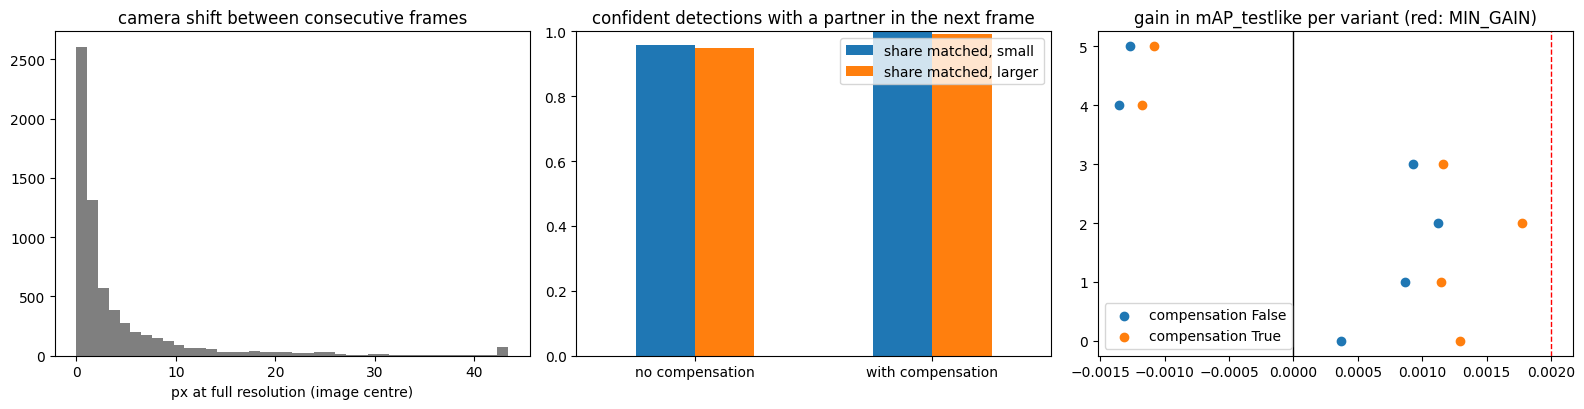

results_temporal_v2.zip written


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].hist(MSTATS.shift_px.clip(upper=np.percentile(MSTATS.shift_px, 99)), bins=40, color="tab:gray")
ax[0].set_title("camera shift between consecutive frames"); ax[0].set_xlabel("px at full resolution (image centre)")
m = MATCH.set_index("motion compensation")[["share matched, small", "share matched, larger"]]
m.index = ["no compensation", "with compensation"]; m.plot.bar(ax=ax[1], rot=0); ax[1].set_title("confident detections with a partner in the next frame"); ax[1].set_ylim(0, 1)
x = TEMP[TEMP["mode"] != "-"].copy(); x["label"] = x["mode"] + " " + x["offsets"] + " thr" + x["thr"].astype(str)
for comp, col in ((False, "tab:blue"), (True, "tab:orange")):
    s_ = x[x.motion_comp == comp]; ax[2].scatter(s_.gain_mAP_testlike, range(len(s_)), c=col, label=f"compensation {comp}")
ax[2].axvline(0, c="k", lw=1); ax[2].axvline(MIN_GAIN, c="r", ls="--", lw=1); ax[2].set_title("gain in mAP_testlike per variant (red: MIN_GAIN)"); ax[2].legend()
plt.tight_layout(); plt.savefig(WORK / f"{TAG}temporal_v2.png", dpi=130); plt.show()
with zipfile.ZipFile(WORK / f"{TAG}results_temporal_v2.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for fn in ("temporal_v2_experiments.csv", "motion_stats.csv", "match_rate.csv", "temporal_v2_config.json", "temporal_v2.png"):
        z.write(WORK / f"{TAG}{fn}", fn)
print("results_temporal_v2.zip written")